# Helicopter Engine Fault Detection (PHM 2024 Data Challenge dataset)
Run the cells from top to bottom. Put `X_train.csv` and `y_train.csv` in the `dataset` folder first.

## 1. Load data (3.4 Data Acquisition)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

X_raw = pd.read_csv("../dataset/X_train.csv")
y_raw = pd.read_csv("../dataset/y_train.csv")

print("X_train shape:", X_raw.shape)
print("y_train shape:", y_raw.shape)

X_train shape: (742625, 8)
y_train shape: (742625, 3)


## 2. Merge sensor readings and labels by `id`
Only the `faulty` column is taken. `trq_margin` is never used, because the label is calculated from it.

In [2]:
df = X_raw.merge(y_raw[['id', 'faulty']], on='id')

print(df.shape)
df.head()

(742625, 9)


,id,trq_measured,oat,mgt,pa,ias,np,ng,faulty
0,0,54.100,2.00000,544.5000,212.1408,74.56250,89.18000,99.6400,1
1,1,49.625,24.22231,578.4844,1625.6400,30.35596,99.55273,91.3866,0
2,2,52.000,7.00000,566.1000,1912.9250,65.62500,100.14000,90.9600,1
3,3,62.400,7.25000,560.1000,277.0632,54.81250,90.64000,100.2800,0
4,4,62.900,23.25000,593.7000,53.6448,73.43750,99.91000,92.1700,0


## 3. Check the data (3.5.1 Data Cleaning)

In [3]:
df.info()
print(df.isnull().sum())
print("Duplicate rows (ignoring id):", df.drop(columns=['id']).duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 742625 entries, 0 to 742624
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            742625 non-null  int64  
 1   trq_measured  742625 non-null  float64
 2   oat           742625 non-null  float64
 3   mgt           742625 non-null  float64
 4   pa            742625 non-null  float64
 5   ias           742625 non-null  float64
 6   np            742625 non-null  float64
 7   ng            742625 non-null  float64
 8   faulty        742625 non-null  int64  
dtypes: float64(7), int64(2)
memory usage: 51.0 MB
id              0
trq_measured    0
oat             0
mgt             0
pa              0
ias             0
np              0
ng              0
faulty          0
dtype: int64
Duplicate rows (ignoring id): 59600


## 4. Remove `id` and duplicate records

In [4]:
data = df.drop(columns=['id']).drop_duplicates()

print("Rows before:", len(df))
print("Rows after :", len(data))

Rows before: 742625
Rows after : 683025


## 5. Summary statistics

In [5]:
data.describe().round(2)

,trq_measured,oat,mgt,pa,ias,np,ng,faulty
count,683025.00,683025.00,683025.00,683025.00,683025.00,683025.00,683025.00,683025.00
mean,65.43,12.35,591.99,466.87,80.69,97.15,95.73,0.37
std,13.46,8.22,40.24,551.90,34.91,4.09,3.66,0.48
min,14.67,-19.25,467.30,-208.39,0.00,85.01,90.00,0.00
25%,56.60,7.25,561.80,116.09,54.12,94.73,92.42,0.00
50%,66.10,13.25,589.40,317.30,90.19,99.71,95.01,0.00
75%,76.00,18.50,622.50,526.69,110.94,100.00,99.93,1.00
max,104.73,36.80,723.40,3097.51,137.56,101.56,101.22,1.00


## 6. Class distribution

faulty
0    429098
1    253927
Name: count, dtype: int64
faulty
0    62.8
1    37.2
Name: proportion, dtype: float64


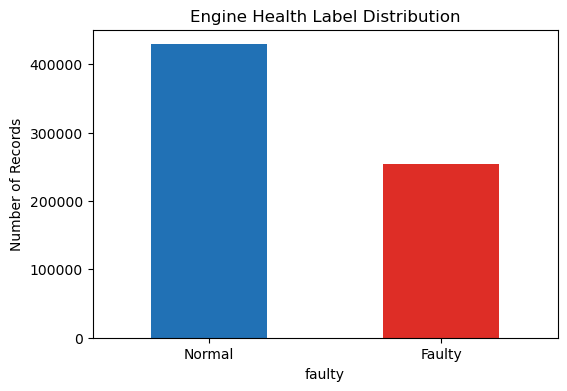

In [6]:
counts = data['faulty'].value_counts()
print(counts)
print((data['faulty'].value_counts(normalize=True) * 100).round(1))

counts.rename({0: 'Normal', 1: 'Faulty'}).plot(kind='bar', color=['#2171b5', '#de2d26'], figsize=(6, 4))
plt.title("Engine Health Label Distribution")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.savefig("../figures/01_class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

## 7. Sensor distributions by class (EDA)

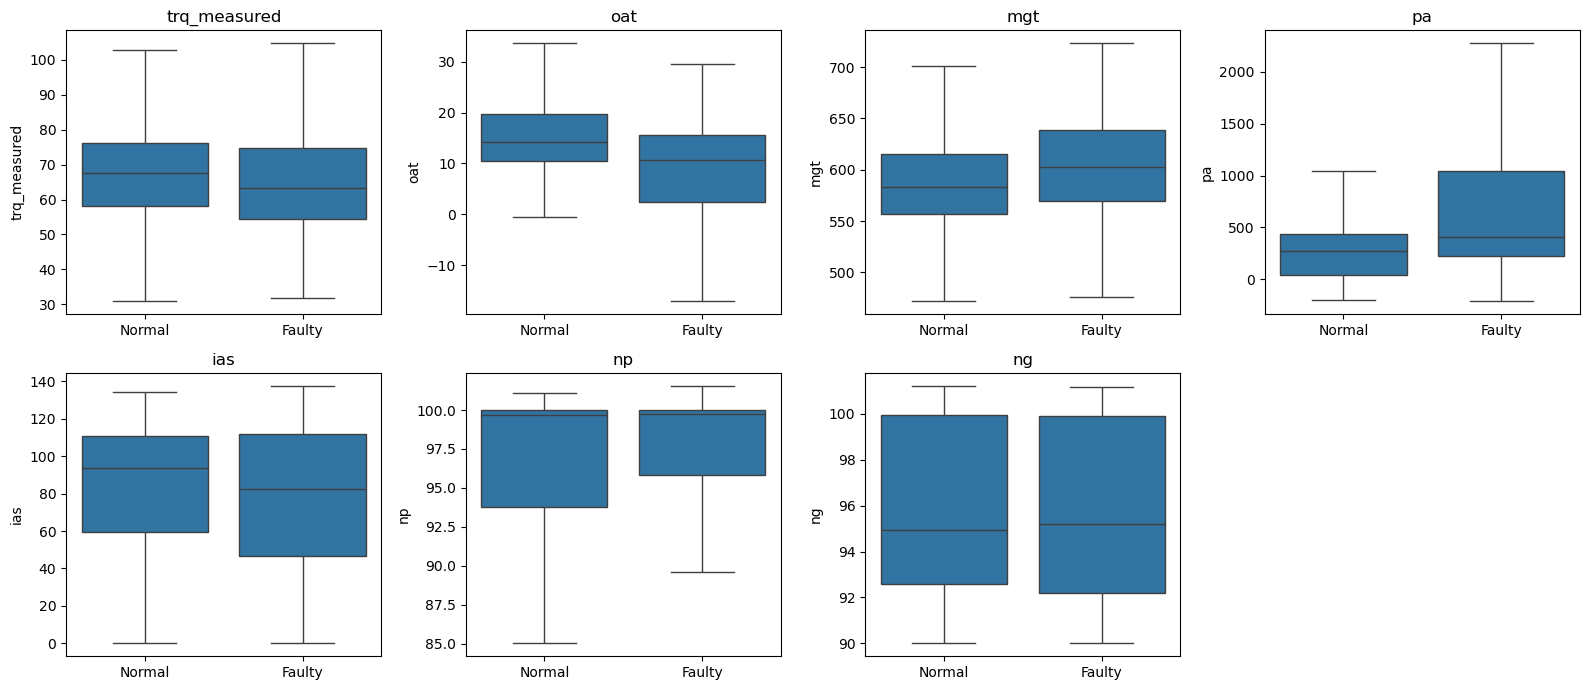

faulty,0,1
trq_measured,66.55,63.53
oat,14.77,8.27
mgt,585.66,602.70
pa,347.76,668.15
ias,82.52,77.58
np,96.84,97.68
ng,95.85,95.52


In [7]:
sensor_columns = ['trq_measured', 'oat', 'mgt', 'pa', 'ias', 'np', 'ng']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, sensor in enumerate(sensor_columns):
    sns.boxplot(data=data, x='faulty', y=sensor, ax=axes[i], showfliers=False)
    axes[i].set_title(sensor)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Normal', 'Faulty'])
    axes[i].set_xlabel("")

axes[-1].axis('off')   # 7 sensors, 8 boxes, so hide the last one
plt.tight_layout()
plt.savefig("../figures/02_sensor_boxplots.png", dpi=150, bbox_inches='tight')
plt.show()

# Average of each sensor for Normal (0) vs Faulty (1)
data.groupby('faulty')[sensor_columns].mean().T.round(2)

## 8. Sensor correlation

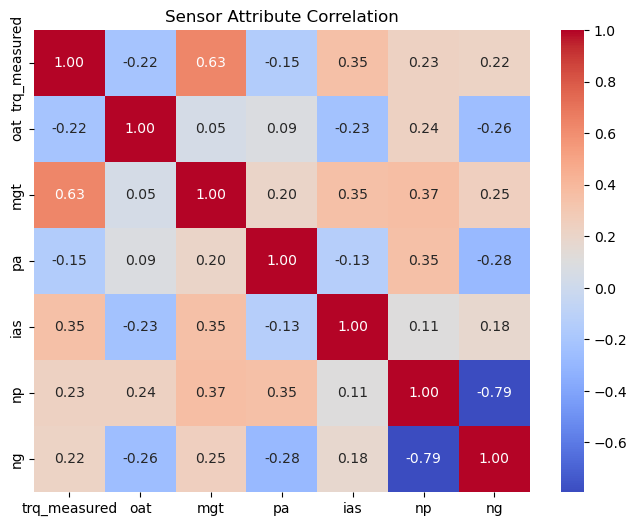

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(data[sensor_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Sensor Attribute Correlation")
plt.savefig("../figures/03_correlation.png", dpi=150, bbox_inches='tight')
plt.show()

## 9. Train-test split 80:20 (3.5.2)
Labels are already 0/1, so no label encoding is needed.

In [9]:
from sklearn.model_selection import train_test_split

X = data[sensor_columns]
y = data['faulty']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (546420, 7)
Testing set : (136605, 7)


## 10. Information Gain with permutation test (3.5.3)
Computed on a 50,000-record sample of the training set, with labels shuffled 20 times to find the chance level.

,Sensor Attribute,Information Gain,Chance Level,Above Chance
1,oat,0.2482,0.0032,True
3,pa,0.1639,0.0034,True
0,trq_measured,0.0787,0.0023,True
5,np,0.0648,0.0034,True
4,ias,0.0507,0.0039,True
6,ng,0.0406,0.0033,True
2,mgt,0.0392,0.0044,True


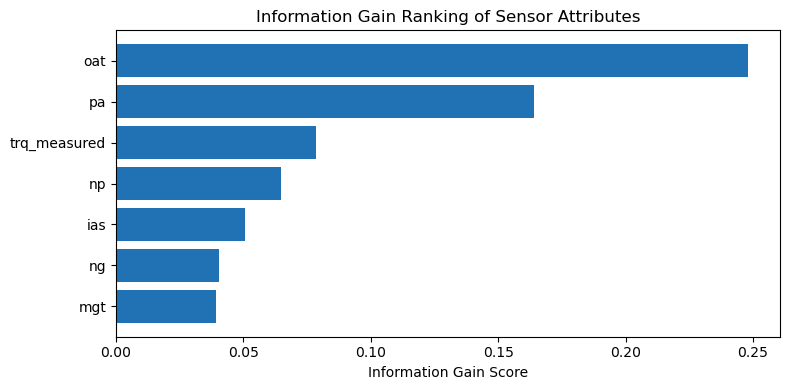

In [10]:
from sklearn.feature_selection import mutual_info_classif

X_ig = X_train.sample(50000, random_state=42)
y_ig = y_train.loc[X_ig.index]

# Real IG scores
real_scores = mutual_info_classif(X_ig, y_ig, random_state=42)

# IG with shuffled labels, 20 times
rng = np.random.default_rng(42)
shuffled_scores = []
for i in range(20):
    fake_labels = rng.permutation(y_ig.values)
    shuffled_scores.append(mutual_info_classif(X_ig, fake_labels, random_state=42))
shuffled_scores = np.array(shuffled_scores)

# Chance level = highest score from shuffled labels
chance_level = shuffled_scores.max(axis=0)

ig_table = pd.DataFrame({
    'Sensor Attribute': sensor_columns,
    'Information Gain': real_scores.round(4),
    'Chance Level': chance_level.round(4),
    'Above Chance': real_scores > chance_level
}).sort_values('Information Gain', ascending=False)

display(ig_table)

plt.figure(figsize=(8, 4))
plt.barh(ig_table['Sensor Attribute'], ig_table['Information Gain'], color='#2171b5')
plt.gca().invert_yaxis()
plt.xlabel("Information Gain Score")
plt.title("Information Gain Ranking of Sensor Attributes")
plt.tight_layout()
plt.savefig("../figures/04_information_gain.png", dpi=150, bbox_inches='tight')
plt.show()

## 11. Scoring function
One function to calculate every metric, so all models are measured the same way.
Precision, recall and F1-score are for the **Faulty** class (1), because catching faulty engines is the main goal.

In [11]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

def get_scores(name, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0)
    }

## 12. Train the models (3.6 Machine Learning Models Development)
Four models are trained on the training set and tested on the testing set:
- **Dummy**: always predicts Normal. It is the baseline, showing the score a model gets without learning anything.
- **Decision Tree**, **Random Forest** and **XGBoost**: the three models from the methodology.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import time

models = {
    'Dummy (always Normal)': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1)
}

predictions = {}
results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    results.append(get_scores(name, predictions[name]))
    print(f"{name}: trained in {time.time() - start:.0f}s")

results_table = pd.DataFrame(results).set_index('Model').round(4)
results_table

Dummy (always Normal): trained in 0s
Decision Tree: trained in 5s
Random Forest: trained in 18s
XGBoost: trained in 6s


,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
Model,,,,,
Dummy (always Normal),0.6282,0.5000,0.0000,0.0000,0.0000
Decision Tree,0.9967,0.9964,0.9960,0.9952,0.9956
Random Forest,0.9993,0.9992,0.9993,0.9988,0.9990
XGBoost,0.9995,0.9995,0.9994,0.9994,0.9994


## 13. Model comparison chart (3.7 Model Evaluation)
Compares accuracy, balanced accuracy and F1-score for every model against the Dummy baseline.

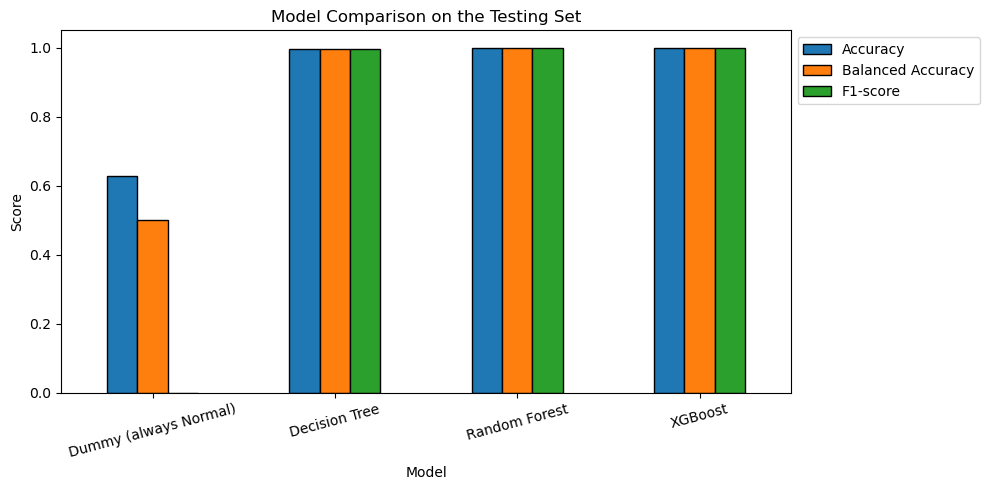

In [13]:
chart = results_table[['Accuracy', 'Balanced Accuracy', 'F1-score']]
ax = chart.plot(kind='bar', figsize=(10, 5), edgecolor='black')
plt.title("Model Comparison on the Testing Set")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("../figures/05_model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## 14. Confusion matrices
Shows how many Normal and Faulty engines each model predicted correctly and wrongly.
- Top-left: Normal predicted as Normal (correct)
- Bottom-right: Faulty predicted as Faulty (correct)
- Top-right: false alarm (Normal predicted as Faulty)
- Bottom-left: **missed fault** (Faulty predicted as Normal), the most dangerous mistake

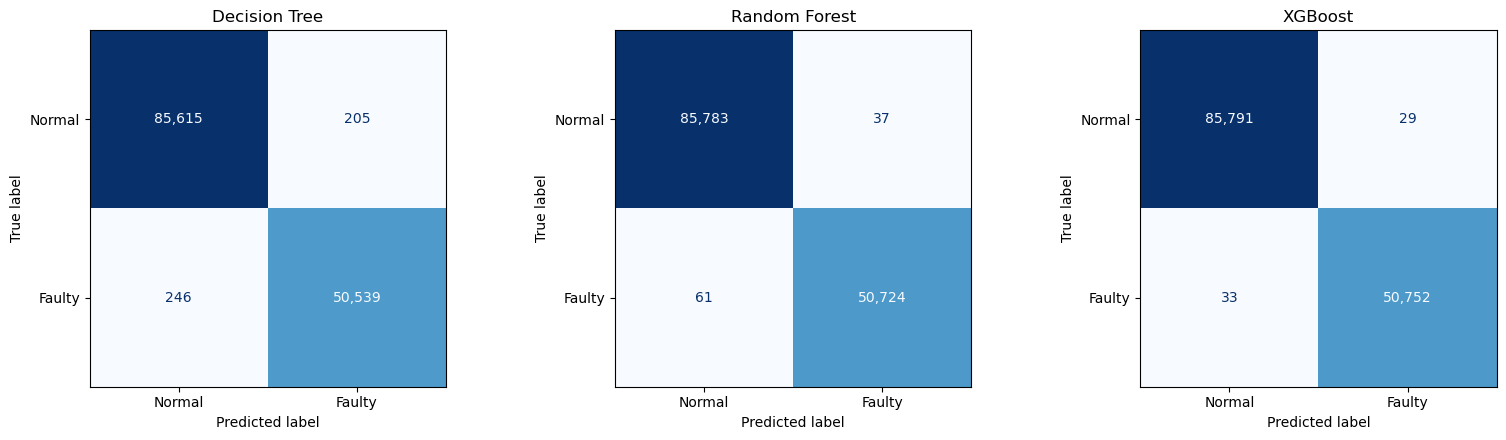

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes, ['Decision Tree', 'Random Forest', 'XGBoost']):
    cm = confusion_matrix(y_test, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Faulty']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format=',')
    ax.set_title(name)

plt.tight_layout()
plt.savefig("../figures/06_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()

## 15. Classification report for each model
Precision, recall and F1-score for both classes.

In [15]:
for name in ['Decision Tree', 'Random Forest', 'XGBoost']:
    print(f"===== {name} =====")
    print(classification_report(y_test, predictions[name],
                                target_names=['Normal', 'Faulty'], digits=4))

===== Decision Tree =====
              precision    recall  f1-score   support

      Normal     0.9971    0.9976    0.9974     85820
      Faulty     0.9960    0.9952    0.9956     50785

    accuracy                         0.9967    136605
   macro avg     0.9965    0.9964    0.9965    136605
weighted avg     0.9967    0.9967    0.9967    136605

===== Random Forest =====
              precision    recall  f1-score   support

      Normal     0.9993    0.9996    0.9994     85820
      Faulty     0.9993    0.9988    0.9990     50785

    accuracy                         0.9993    136605
   macro avg     0.9993    0.9992    0.9992    136605
weighted avg     0.9993    0.9993    0.9993    136605

===== XGBoost =====
              precision    recall  f1-score   support

      Normal     0.9996    0.9997    0.9996     85820
      Faulty     0.9994    0.9994    0.9994     50785

    accuracy                         0.9995    136605
   macro avg     0.9995    0.9995    0.9995    136605
we

## 16. Experiment: which sensors does the model really need?
The accuracy above is very high, so this checks why. XGBoost is trained three times with different sensor groups:
- **All 7 sensors**: the main result
- **Engine sensors only** (torque, mean gas temperature, gas generator speed, power turbine speed): readings from the engine itself
- **Weather and altitude only** (outside air temperature, pressure altitude): no engine readings at all

If weather and altitude alone give a high score, the model can partly guess faults from flight conditions instead of engine behaviour.

In [16]:
sensor_groups = {
    'All 7 sensors': ['trq_measured', 'oat', 'mgt', 'pa', 'ias', 'np', 'ng'],
    'Engine sensors only': ['trq_measured', 'mgt', 'np', 'ng'],
    'Weather and altitude only': ['oat', 'pa'],
}

group_results = []
for name, cols in sensor_groups.items():
    model = XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    model.fit(X_train[cols], y_train)
    group_results.append(get_scores(name, model.predict(X_test[cols])))

group_table = pd.DataFrame(group_results).set_index('Model').round(4)
group_table

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
Model,,,,,
All 7 sensors,0.9995,0.9995,0.9994,0.9994,0.9994
Engine sensors only,0.9211,0.9136,0.9015,0.8843,0.8929
Weather and altitude only,0.9553,0.9527,0.9377,0.9425,0.9401


## 17. Experiment: with and without SMOTE (3.5.4 Data Balancing)
The classes are only mildly imbalanced (about 63% Normal, 37% Faulty), so this checks whether SMOTE is needed.
SMOTE is applied to the **training set only**. The testing set is never changed.

In [17]:
from imblearn.over_sampling import SMOTE

X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE :", pd.Series(y_train_smote).value_counts().to_dict())

smote_model = XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1)
smote_model.fit(X_train_smote, y_train_smote)

smote_table = pd.DataFrame([
    get_scores('XGBoost without SMOTE', predictions['XGBoost']),
    get_scores('XGBoost with SMOTE', smote_model.predict(X_test)),
]).set_index('Model').round(4)
smote_table

Before SMOTE: {0: 343278, 1: 203142}
After SMOTE : {1: 343278, 0: 343278}


,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
Model,,,,,
XGBoost without SMOTE,0.9995,0.9995,0.9994,0.9994,0.9994
XGBoost with SMOTE,0.9995,0.9996,0.9992,0.9996,0.9994


## 18. Feature importance (3.7 Model Interpretation)
Shows which sensors Random Forest and XGBoost relied on most when making predictions.

,Decision Tree,Random Forest,XGBoost
oat,0.4184,0.3469,0.2030
pa,0.1429,0.1832,0.0730
trq_measured,0.0868,0.1153,0.1249
mgt,0.1324,0.1075,0.1668
np,0.1393,0.0923,0.2503
ng,0.0466,0.0849,0.1364
ias,0.0336,0.0699,0.0457


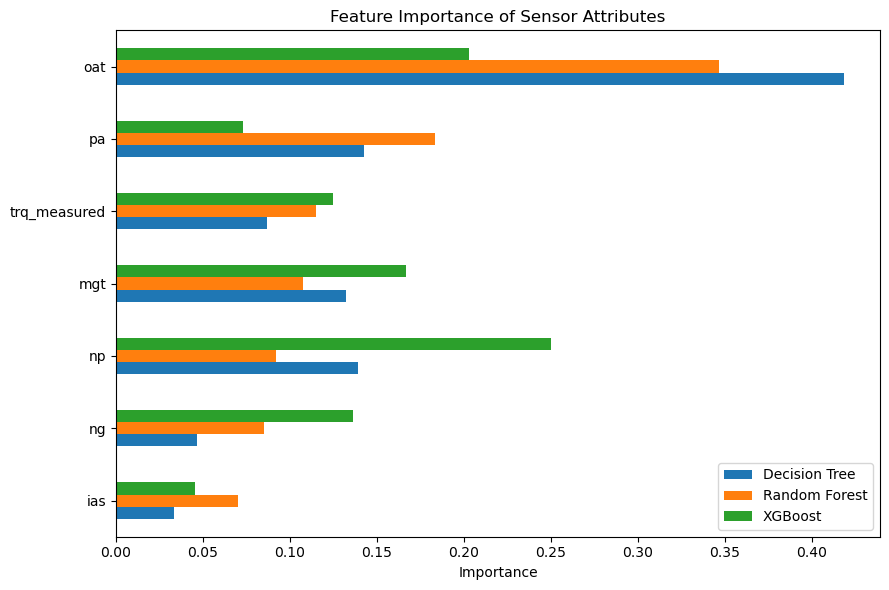

In [20]:
# Feature importance for all three models
importance = pd.DataFrame({
    'Decision Tree': models['Decision Tree'].feature_importances_,
    'Random Forest': models['Random Forest'].feature_importances_,
    'XGBoost': models['XGBoost'].feature_importances_,
}, index=sensor_columns).round(4).sort_values('Random Forest', ascending=False)

display(importance)

importance.sort_values('Random Forest').plot(kind='barh', figsize=(9, 6))
plt.title("Feature Importance of Sensor Attributes")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../figures/07_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

## 19. Save the best model for the prototype
Saves XGBoost (the best model) so the Streamlit prototype can load it later.

In [22]:
import joblib
import json

best_model = models['XGBoost']

# 1. Save the trained model
joblib.dump(best_model, "../model/xgboost_model.joblib")

# 2. Save information the prototype needs
y_pred_best = best_model.predict(X_test)
model_info = {
    "model_name": "XGBoost",
    "features": sensor_columns,
    "ranges": {col: [round(float(X_train[col].min()), 2), round(float(X_train[col].max()), 2)]
               for col in sensor_columns},
    "test_scores": {
        "accuracy": round(accuracy_score(y_test, y_pred_best), 4),
        "f1_score": round(f1_score(y_test, y_pred_best), 4),
        "engine_sensors_only_accuracy": round(float(group_table.loc['Engine sensors only', 'Accuracy']), 4),
    },
}
with open("../model/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

# 3. Save 1,000 test rows with their real label, for the prototype demo and testing
test_samples = X_test.copy()
test_samples['actual_label'] = y_test.values
test_samples['notebook_prediction'] = y_pred_best
test_samples.sample(1000, random_state=42).to_csv("../model/test_samples.csv", index=False)

print("Saved to the model folder:")
print(" - xgboost_model.joblib")
print(" - model_info.json")
print(" - test_samples.csv (1,000 test rows)")
print("Test scores:", model_info["test_scores"])

Saved to the model folder:
 - xgboost_model.joblib
 - model_info.json
 - test_samples.csv (1,000 test rows)
Test scores: {'accuracy': 0.9995, 'f1_score': 0.9994, 'engine_sensors_only_accuracy': 0.9211}
